<a href="https://colab.research.google.com/github/pouryaheydari96/hybrid-topology-v1.3.1/blob/main/Copy_of_advanced_wheel_gan_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Wheel GAN — Colab Environment Test & Design Analysis

Cleaned, runnable version. Run the cells top to bottom (Runtime → Run all).

**What this notebook does**

1. Validates the Colab environment and benchmarks CPU vs GPU.
2. Defines a conditional GAN (generator + discriminator) for 128x128 wheel images and
   runs a forward-pass smoke test. **Note: there is no training loop and no dataset — the
   GAN is defined and shape-checked only.** The wheels below come from the procedural
   generator in step 3, not from the network.
3. Defines a procedural wheel generation engine (NumPy) with six patterns.
4. Analyses one generated wheel: structural metrics, radial profile, and heuristic
   mechanical scores.

**Changes from the original notebook**

- The duplicated 29k-character mega-cell was split into sections and de-duplicated.
- The copy of `UltimateDesignAnalyzer` inside the mega-cell was truncated mid-method
  (`comprehensive_analysis` had no `return`, and three helpers were missing). It has been
  replaced by the complete version, defined exactly once.
- The cell that failed with `ValueError: keyword ha is not recognized` was removed; the
  corrected version is kept.
- Unused heavy imports (gradio, torchsummary, plotly, seaborn, ipywidgets, PIL) were
  dropped — nothing in the notebook used them.
- Seeds are set so runs are reproducible; figures are closed after display.

## 1. Setup

In [ ]:
# ==============================================================================
# SETUP — imports, performance flags, seeds
# ==============================================================================

import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import psutil
import scipy.ndimage
from scipy import ndimage

import torch
import torch.nn as nn
import torch.optim as optim  # kept for when a training loop is added

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Performance
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False

print("Libraries imported.")
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU accelerated: {torch.cuda.get_device_name(0)}")
else:
    print("Running on CPU — Runtime > Change runtime type > GPU for the benchmarks to mean anything.")

Libraries imported.
Running on CPU — Runtime > Change runtime type > GPU for the benchmarks to mean anything.


In [ ]:
import torch

gpu_available = torch.cuda.is_available()
print(f"GPU Available: {gpu_available}")
if gpu_available:
    print(f"Active GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
else:
    print("GPU is still not detected. Please ensure you selected 'T4 GPU' (or another GPU) in Runtime > Change runtime type.")

GPU Available: False
GPU is still not detected. Please ensure you selected 'T4 GPU' (or another GPU) in Runtime > Change runtime type.


In [ ]:
import torch
print(f"torch.cuda.is_available() is currently: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

torch.cuda.is_available() is currently: False


In [ ]:
import os
import torch

print(f"CUDA (GPU) Available after restart: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
else:
    print("Still on CPU. To trigger a programmatic restart of the runtime, run: os.kill(os.getpid(), 9)")

CUDA (GPU) Available after restart: False
Still on CPU. To trigger a programmatic restart of the runtime, run: os.kill(os.getpid(), 9)


## 2. Environment validation & benchmarks

Optional. Skip this cell if you only want the wheel pipeline.

In [ ]:
# 🔍 COMPREHENSIVE ENVIRONMENT VALIDATION
print("\n" + "="*70)
print("🔍 COMPREHENSIVE COLAB ENVIRONMENT VALIDATION")
print("="*70)

def ultimate_environment_validation():
    """Ultimate environment validation with performance benchmarking"""

    validation_results = {}

    # 1. PyTorch Ecosystem
    print("🧪 PyTorch Ecosystem Analysis:")
    print(f"   ✅ PyTorch: {torch.__version__}")
    print(f"   ✅ CUDA: {torch.version.cuda if torch.cuda.is_available() else 'N/A'}")
    print(f"   ✅ cuDNN: {torch.backends.cudnn.version() if torch.cuda.is_available() else 'N/A'}")

    # 2. GPU Analysis
    if torch.cuda.is_available():
        gpu_props = torch.cuda.get_device_properties(0)
        print(f"   ✅ GPU: {gpu_props.name}")
        print(f"   ✅ Memory: {gpu_props.total_memory / 1e9:.1f} GB")
        print(f"   ✅ Compute: {gpu_props.major}.{gpu_props.minor}")
        print(f"   ✅ Multiprocessors: {gpu_props.multi_processor_count}")
        validation_results['gpu_memory_gb'] = gpu_props.total_memory / 1e9
    else:
        print("   ⚠️  Running on CPU - Consider enabling GPU for optimal performance")

    # 3. System Resources
    print("\n💻 System Resource Analysis:")
    cpu_cores = psutil.cpu_count()
    cpu_physical = psutil.cpu_count(logical=False)
    ram_total = psutil.virtual_memory().total / 1e9
    ram_available = psutil.virtual_memory().available / 1e9
    disk_free = psutil.disk_usage('/').free / 1e9

    print(f"   ✅ CPU Cores: {cpu_physical} Physical, {cpu_cores} Logical")
    print(f"   ✅ RAM: {ram_available:.1f} GB / {ram_total:.1f} GB Available")
    print(f"   ✅ Disk: {disk_free:.1f} GB Free")

    validation_results.update({
        'cpu_cores': cpu_cores,
        'ram_gb': ram_total,
        'disk_free_gb': disk_free
    })

    # 4. Performance Benchmarks
    print("\n⚡ Performance Benchmarks:")

    # CPU Performance
    start_time = time.time()
    for _ in range(100):
        a = np.random.rand(500, 500)
        b = np.random.rand(500, 500)
        c = np.dot(a, b)
    cpu_time = time.time() - start_time
    print(f"   ✅ CPU Matrix Mult (100x): {cpu_time:.3f}s")

    # GPU Performance (if available)
    if torch.cuda.is_available():
        start_time = time.time()
        a_gpu = torch.randn(500, 500, device='cuda')
        b_gpu = torch.randn(500, 500, device='cuda')

        # Warmup
        for _ in range(10):
            _ = torch.matmul(a_gpu, b_gpu)
        torch.cuda.synchronize()

        # Benchmark
        start_time = time.time()
        for _ in range(100):
            c_gpu = torch.matmul(a_gpu, b_gpu)
        torch.cuda.synchronize()
        gpu_time = time.time() - start_time

        print(f"   ✅ GPU Matrix Mult (100x): {gpu_time:.3f}s")
        print(f"   🚀 GPU Speedup: {cpu_time/gpu_time:.1f}x")
        validation_results['gpu_speedup'] = cpu_time / gpu_time
    else:
        validation_results['gpu_speedup'] = 1.0

    # 5. Memory Bandwidth Test
    if torch.cuda.is_available():
        print("\n📊 Memory Bandwidth Analysis:")
        sizes = [1024, 2048, 4096]
        for size in sizes:
            tensor = torch.randn(size, size, device='cuda')
            start_time = time.time()
            for _ in range(50):
                result = tensor @ tensor.T
            torch.cuda.synchronize()
            elapsed = time.time() - start_time
            gflops = (2.0 * size**3 * 50) / (elapsed * 1e9)
            print(f"   ✅ {size}x{size}: {gflops:.1f} GFLOPs")

    return validation_results

# Run comprehensive validation
validation_results = ultimate_environment_validation()


🔍 COMPREHENSIVE COLAB ENVIRONMENT VALIDATION
🧪 PyTorch Ecosystem Analysis:
   ✅ PyTorch: 2.9.0+cpu
   ✅ CUDA: N/A
   ✅ cuDNN: N/A
   ⚠️  Running on CPU - Consider enabling GPU for optimal performance

💻 System Resource Analysis:
   ✅ CPU Cores: 12 Physical, 24 Logical
   ✅ RAM: 48.2 GB / 50.5 GB Available
   ✅ Disk: 221.1 GB Free

⚡ Performance Benchmarks:
   ✅ CPU Matrix Mult (100x): 6.924s


## 3. GAN architecture

Config, attention/residual building blocks, generator and discriminator.

In [ ]:
# Hyperparameter Configuration
class Config:
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    IMG_SIZE = 128
    Z_DIM = 256
    CONDITION_DIM = 4  # [volume_fraction, num_spokes, complexity, symmetry]
    BATCH_SIZE = 32
    BASE_FILTERS = 64
    LEARNING_RATE = 2e-4
    BETA1 = 0.5
    BETA2 = 0.999

config = Config()

class SelfAttention(nn.Module):
    """Self-Attention Mechanism for improved global coherence"""

    def __init__(self, in_dim):
        super().__init__()
        self.channel_in = in_dim

        self.query = nn.Conv2d(in_dim, in_dim // 8, 1)
        self.key = nn.Conv2d(in_dim, in_dim // 8, 1)
        self.value = nn.Conv2d(in_dim, in_dim, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        batch_size, C, width, height = x.size()

        # Project to query, key, value
        proj_query = self.query(x).view(batch_size, -1, width * height).permute(0, 2, 1)
        proj_key = self.key(x).view(batch_size, -1, width * height)

        # Calculate attention
        energy = torch.bmm(proj_query, proj_key)
        attention = self.softmax(energy)

        proj_value = self.value(x).view(batch_size, -1, width * height)

        out = torch.bmm(proj_value, attention.permute(0, 2, 1))
        out = out.view(batch_size, C, width, height)

        out = self.gamma * out + x
        return out

class ResidualBlock(nn.Module):
    """Residual Block with Pre-activation"""

    def __init__(self, channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.BatchNorm2d(channels),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(channels, channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(channels, channels, 3, 1, 1, bias=False),
        )

    def forward(self, x):
        return x + self.block(x)

class UltimateGenerator(nn.Module):
    """Ultimate Generator with Residual Blocks and Attention"""

    def __init__(self, z_dim=256, condition_dim=4, img_size=128, base_filters=64):
        super().__init__()
        self.z_dim = z_dim
        self.condition_dim = condition_dim
        self.img_size = img_size

        # Enhanced Condition Processing
        self.condition_net = nn.Sequential(
            nn.Linear(condition_dim, z_dim // 2),
            nn.BatchNorm1d(z_dim // 2),
            nn.LeakyReLU(0.2, True),
            nn.Dropout(0.1),
            nn.Linear(z_dim // 2, z_dim),
            nn.BatchNorm1d(z_dim),
            nn.LeakyReLU(0.2, True),
            nn.Dropout(0.1),
        )

        # Initial Projection
        self.init_size = img_size // 16
        self.fc = nn.Sequential(
            nn.Linear(z_dim * 2, base_filters * 16 * self.init_size * self.init_size),
            nn.BatchNorm1d(base_filters * 16 * self.init_size * self.init_size),
            nn.ReLU(True)
        )

        # Progressive Upsampling with Residual Blocks
        self.upsample_blocks = nn.ModuleList([
            # 8x8 -> 16x16
            self._residual_upsample_block(base_filters * 16, base_filters * 8),
            # 16x16 -> 32x32
            self._residual_upsample_block(base_filters * 8, base_filters * 4),
            # 32x32 -> 64x64
            self._residual_upsample_block(base_filters * 4, base_filters * 2),
            # 64x64 -> 128x128
            self._residual_upsample_block(base_filters * 2, base_filters),
        ])

        # Self-Attention at 64x64 resolution
        self.attention = SelfAttention(base_filters * 2)

        # Final convolution
        self.final_conv = nn.Sequential(
            nn.Conv2d(base_filters, base_filters // 2, 3, 1, 1),
            nn.BatchNorm2d(base_filters // 2),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(base_filters // 2, 1, 3, 1, 1),
            nn.Sigmoid()
        )

    def _residual_upsample_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, True),
            ResidualBlock(out_channels),
            nn.Dropout2d(0.1)
        )

    def forward(self, z, conditions):
        batch_size = z.size(0)

        # Enhanced condition processing
        cond_proj = self.condition_net(conditions)

        # Concatenate and project
        combined = torch.cat([z, cond_proj], dim=1)
        x = self.fc(combined)
        x = x.view(batch_size, -1, self.init_size, self.init_size)

        # Progressive upsampling
        for i, block in enumerate(self.upsample_blocks):
            x = block(x)
            # Apply attention at 64x64 resolution
            if x.size(-1) == 64:
                x = self.attention(x)

        # Final convolution
        x = self.final_conv(x)

        return x

class UltimateDiscriminator(nn.Module):
    """Ultimate Discriminator with Spectral Normalization and Attention"""

    def __init__(self, img_size=128, condition_dim=4, base_filters=64):
        super().__init__()
        self.img_size = img_size

        # Feature extraction backbone
        self.conv_blocks = nn.Sequential(
            # 128x128 -> 64x64
            self._downsample_block(1, base_filters, batch_norm=False),
            # 64x64 -> 32x32
            self._downsample_block(base_filters, base_filters * 2),
            # 32x32 -> 16x16
            self._downsample_block(base_filters * 2, base_filters * 4),
        )

        # Attention at 32x32
        self.attention = SelfAttention(base_filters * 4)

        # Continue downsampling
        self.conv_blocks_2 = nn.Sequential(
            # 16x16 -> 8x8
            self._downsample_block(base_filters * 4, base_filters * 8),
            # 8x8 -> 4x4
            self._downsample_block(base_filters * 8, base_filters * 16),
        )

        # Condition projection
        self.condition_net = nn.Sequential(
            nn.Linear(condition_dim, base_filters * 16),
            nn.LeakyReLU(0.2, True),
            nn.Linear(base_filters * 16, base_filters * 16),
            nn.LeakyReLU(0.2, True),
        )

        # Final classification
        self.classifier = nn.Sequential(
            nn.Conv2d(base_filters * 16 * 2, base_filters * 16, 3, 1, 1),
            nn.BatchNorm2d(base_filters * 16),
            nn.LeakyReLU(0.2, True),
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(base_filters * 16, 1, 1)
        )

    def _downsample_block(self, in_channels, out_channels, batch_norm=True):
        layers = [
            nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, True)
        ]
        if batch_norm:
            layers.insert(1, nn.BatchNorm2d(out_channels))
        return nn.Sequential(*layers)

    def forward(self, img, conditions):
        batch_size = img.size(0)

        # Extract features
        x = self.conv_blocks(img)
        x = self.attention(x)
        x = self.conv_blocks_2(x)

        # Process conditions
        cond_proj = self.condition_net(conditions)
        cond_proj = cond_proj.view(batch_size, -1, 1, 1)
        cond_proj = cond_proj.expand(-1, -1, x.size(2), x.size(3))

        # Concatenate and classify
        combined = torch.cat([x, cond_proj], dim=1)
        output = self.classifier(combined)

        return output.view(batch_size, -1)

### 3a. Forward-pass smoke test

Builds both networks, pushes one batch through, and reports parameter counts.

In [ ]:
# Test Ultimate Models
print("🧠 Testing Ultimate Models...")
try:
    ultimate_G = UltimateGenerator().to(config.DEVICE)
    ultimate_D = UltimateDiscriminator().to(config.DEVICE)

    # Test forward/backward
    z_test = torch.randn(8, config.Z_DIM, device=config.DEVICE)
    conditions_test = torch.tensor([
        [0.2, 4, 0.3, 0.9],
        [0.25, 6, 0.5, 0.8],
        [0.3, 8, 0.7, 0.7],
        [0.35, 10, 0.9, 0.6],
        [0.2, 5, 0.4, 0.85],
        [0.28, 7, 0.6, 0.75],
        [0.32, 9, 0.8, 0.65],
        [0.38, 12, 1.0, 0.5]
    ], device=config.DEVICE, dtype=torch.float32)

    # Forward pass
    with torch.no_grad():
        fake_imgs = ultimate_G(z_test, conditions_test)
        d_output = ultimate_D(fake_imgs, conditions_test)

    print(f"✅ Ultimate Generator: {fake_imgs.shape}")
    print(f"✅ Ultimate Discriminator: {d_output.shape}")

    # Parameter analysis
    g_params = sum(p.numel() for p in ultimate_G.parameters())
    d_params = sum(p.numel() for p in ultimate_D.parameters())
    total_params = g_params + d_params

    print(f"📊 Model Complexity Analysis:")
    print(f"   🎯 Generator: {g_params:,} ({g_params/1e6:.2f}M)")
    print(f"   🎯 Discriminator: {d_params:,} ({d_params/1e6:.2f}M)")
    print(f"   🎯 Total: {total_params:,} ({total_params/1e6:.2f}M)")

    # Memory footprint
    if torch.cuda.is_available():
        memory_allocated = torch.cuda.memory_allocated() / 1e6
        memory_cached = torch.cuda.memory_reserved() / 1e6
        print(f"   💾 GPU Memory - Allocated: {memory_allocated:.1f} MB")
        print(f"   💾 GPU Memory - Cached: {memory_cached:.1f} MB")

except Exception as e:
    print(f"❌ Ultimate model test failed: {e}")

🧠 Testing Ultimate Models...
✅ Ultimate Generator: torch.Size([8, 1, 128, 128])
✅ Ultimate Discriminator: torch.Size([8, 1])
📊 Model Complexity Analysis:
   🎯 Generator: 46,364,450 (46.36M)
   🎯 Discriminator: 31,161,410 (31.16M)
   🎯 Total: 77,525,860 (77.53M)


## 4. Procedural wheel generation engine

Six patterns (`standard`, `web`, `spiral`, `sport`, `luxury`, `hybrid`), each driven by volume fraction, spoke count, complexity and symmetry.

In [ ]:
# 🎨 ADVANCED WHEEL GENERATION ENGINE
print("\n🎨 Advanced Wheel Generation Engine...")

class UltimateWheelGenerator:
    """Ultimate Wheel Generation Engine with Advanced Algorithms"""

    def __init__(self):
        self.patterns = {
            'standard': self._generate_standard,
            'web': self._generate_web,
            'spiral': self._generate_spiral,
            'hybrid': self._generate_hybrid,
            'sport': self._generate_sport,
            'luxury': self._generate_luxury
        }

    def generate_wheel(self, vol_frac=0.25, num_spokes=6, size=128,
                      pattern_type="standard", complexity=0.5, symmetry=0.8):
        """Generate wheel with advanced parameters"""

        if pattern_type not in self.patterns:
            pattern_type = 'standard'

        return self.patterns[pattern_type](vol_frac, num_spokes, size, complexity, symmetry)

    def _generate_standard(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Standard spoke pattern with adaptive geometry"""
        y, x = np.ogrid[-size//2:size//2, -size//2:size//2]
        r = np.sqrt(x**2 + y**2)
        theta = np.arctan2(y, x)

        img = np.zeros((size, size))

        # Adaptive hub with complexity
        hub_radius = size * (0.08 + 0.04 * complexity)
        img[r < hub_radius] = 1.0

        # Smart rim design
        rim_inner = size * (0.32 + 0.08 * complexity)
        rim_thickness = size * (0.03 + 0.02 * complexity)
        rim_outer = rim_inner + rim_thickness
        rim_mask = (r >= rim_inner) & (r <= rim_outer)
        img[rim_mask] = 1.0

        # Advanced spoke system
        if num_spokes > 0:
            spoke_width_base = max(1.0, size * 0.012)
            spoke_width = spoke_width_base * (1 + 0.5 * complexity)
            spoke_curvature = complexity * 0.15

            spoke_angles = np.linspace(0, 2*np.pi, num_spokes, endpoint=False)

            for i, angle in enumerate(spoke_angles):
                # Apply curvature and symmetry variations
                symmetry_factor = 1.0 - (1.0 - symmetry) * 0.3
                curved_angle = angle + spoke_curvature * np.sin(r / rim_inner * np.pi * 2) * symmetry_factor

                angle_diff = np.abs(np.mod(theta - curved_angle + np.pi, 2*np.pi) - np.pi)

                # Variable spoke width along radius
                radial_width_factor = 0.5 + 0.5 * (r - hub_radius) / (rim_inner - hub_radius)
                current_spoke_width = spoke_width * radial_width_factor

                spoke_mask = (angle_diff < current_spoke_width/size * np.pi) & \
                            (r >= hub_radius * 1.1) & (r <= rim_inner * 0.95)
                img[spoke_mask] = 1.0

        return self._advanced_volume_adjustment(img, vol_frac)

    def _generate_web(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Complex web pattern with radial and circular elements"""
        y, x = np.ogrid[-size//2:size//2, -size//2:size//2]
        r = np.sqrt(x**2 + y**2)
        theta = np.arctan2(y, x)

        img = np.zeros((size, size))

        # Web parameters
        web_density = 0.2 + 0.6 * complexity
        web_radius = size * 0.38

        # Primary radial spokes
        primary_spokes = max(8, int(num_spokes * (1.2 + 0.8 * complexity)))
        secondary_spokes = int(primary_spokes * (0.5 + 0.5 * complexity))

        # Primary spokes
        for angle in np.linspace(0, 2*np.pi, primary_spokes, endpoint=False):
            angle_diff = np.abs(np.mod(theta - angle + np.pi, 2*np.pi) - np.pi)
            spoke_width = size * 0.006
            spoke_mask = (angle_diff < spoke_width/size * np.pi) & (r < web_radius)
            img[spoke_mask] = 1.0

        # Secondary spokes (rotated)
        secondary_phase = np.pi / primary_spokes
        for angle in np.linspace(0, 2*np.pi, secondary_spokes, endpoint=False):
            angle += secondary_phase
            angle_diff = np.abs(np.mod(theta - angle + np.pi, 2*np.pi) - np.pi)
            spoke_width = size * 0.004
            spoke_mask = (angle_diff < spoke_width/size * np.pi) & (r < web_radius * 0.7)
            img[spoke_mask] = 1.0

        # Concentric rings
        ring_count = max(2, int(4 * complexity))
        for i in range(1, ring_count + 1):
            ring_radius = web_radius * (i / ring_count)
            ring_thickness = size * (0.008 + 0.004 * complexity)
            ring_mask = (r >= ring_radius - ring_thickness) & (r <= ring_radius + ring_thickness)
            img[ring_mask] = 1.0

        return self._advanced_volume_adjustment(img, vol_frac)

    def _generate_spiral(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Spiral pattern with mathematical elegance"""
        y, x = np.ogrid[-size//2:size//2, -size//2:size//2]
        r = np.sqrt(x**2 + y**2)
        theta = np.arctan2(y, x)

        img = np.zeros((size, size))

        # Multiple intertwined spirals
        spiral_count = max(2, int(3 + 4 * complexity))
        spiral_tightness = 1.5 + 2.5 * complexity

        for spiral_idx in range(spiral_count):
            phase = 2 * np.pi * spiral_idx / spiral_count
            # Fibonacci-like spiral for natural appearance
            spiral = (theta + phase - spiral_tightness * np.log(r + 1)) % (2 * np.pi)

            spiral_width = size * (0.01 + 0.01 * complexity)
            spiral_mask = (np.abs(spiral - np.pi) < spiral_width) & (r < size * 0.35)
            img[spiral_mask] = 1.0

        return self._advanced_volume_adjustment(img, vol_frac)

    def _generate_sport(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Sport-oriented pattern with aggressive design"""
        y, x = np.ogrid[-size//2:size//2, -size//2:size//2]
        r = np.sqrt(x**2 + y**2)
        theta = np.arctan2(y, x)

        img = np.zeros((size, size))

        # Minimalist hub
        hub_radius = size * 0.06
        img[r < hub_radius] = 1.0

        # Aggressive rim
        rim_inner = size * 0.35
        rim_thickness = size * 0.025
        rim_outer = rim_inner + rim_thickness
        img[(r >= rim_inner) & (r <= rim_outer)] = 1.0

        # Asymmetric spoke pattern for sport look
        spoke_count = max(5, int(num_spokes * 0.8))
        spoke_angles = np.linspace(0, 2*np.pi, spoke_count, endpoint=False)

        for i, angle in enumerate(spoke_angles):
            # Varying spoke widths for dynamic look
            spoke_width = size * (0.015 + 0.01 * np.sin(i * np.pi / spoke_count))
            angle_diff = np.abs(np.mod(theta - angle + np.pi, 2*np.pi) - np.pi)

            spoke_mask = (angle_diff < spoke_width/size * np.pi) & \
                        (r >= hub_radius * 1.2) & (r <= rim_inner * 0.9)
            img[spoke_mask] = 1.0

        return self._advanced_volume_adjustment(img, vol_frac)

    def _generate_luxury(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Luxury pattern with intricate details"""
        # Combine web and standard patterns with fine details
        base_img = self._generate_standard(vol_frac * 0.7, num_spokes, size, complexity, symmetry)
        detail_img = self._generate_web(vol_frac * 0.3, num_spokes * 2, size, complexity * 1.2, symmetry)

        luxury_img = np.maximum(base_img, detail_img * 0.8)
        return self._advanced_volume_adjustment(luxury_img, vol_frac)

    def _generate_hybrid(self, vol_frac, num_spokes, size, complexity, symmetry):
        """Intelligent hybrid pattern combination"""
        # Adaptive hybrid based on complexity
        if complexity < 0.3:
            primary = self._generate_standard(vol_frac * 0.6, num_spokes, size, complexity, symmetry)
            secondary = self._generate_web(vol_frac * 0.4, num_spokes, size, complexity, symmetry)
        elif complexity < 0.7:
            primary = self._generate_web(vol_frac * 0.5, num_spokes, size, complexity, symmetry)
            secondary = self._generate_spiral(vol_frac * 0.5, num_spokes, size, complexity, symmetry)
        else:
            primary = self._generate_spiral(vol_frac * 0.6, num_spokes, size, complexity, symmetry)
            secondary = self._generate_sport(vol_frac * 0.4, num_spokes, size, complexity, symmetry)

        hybrid_img = np.maximum(primary, secondary)
        return self._advanced_volume_adjustment(hybrid_img, vol_frac)

    def _advanced_volume_adjustment(self, img, target_vf):
        """Advanced volume fraction adjustment with morphological operations"""
        from scipy import ndimage

        current_vf = img.mean()
        tolerance = 0.003

        if abs(current_vf - target_vf) < tolerance:
            return self._apply_final_touches(img)

        img_adj = img.copy().astype(np.float32)

        # Use distance transform for intelligent material addition/removal
        if current_vf < target_vf:
            # Add material near existing structures (prioritize connectivity)
            distance_map = ndimage.distance_transform_edt(1 - img_adj)
            addition_candidates = (distance_map <= 2) & (img_adj == 0)

            if np.any(addition_candidates):
                required_pixels = int((target_vf - current_vf) * img_adj.size)
                candidate_indices = np.where(addition_candidates)

                if len(candidate_indices[0]) > 0:
                    # Prioritize closer pixels
                    candidate_distances = distance_map[addition_candidates]
                    probabilities = 1.0 / (candidate_distances + 1e-8)
                    probabilities /= probabilities.sum()

                    selected_indices = np.random.choice(
                        len(candidate_indices[0]),
                        size=min(required_pixels, len(candidate_indices[0])),
                        replace=False,
                        p=probabilities
                    )

                    img_adj[candidate_indices[0][selected_indices],
                           candidate_indices[1][selected_indices]] = 1.0

        else:
            # Remove material from isolated areas (preserve connectivity)
            labeled, num_features = ndimage.label(img_adj > 0.5)
            if num_features > 0:
                component_sizes = np.array([np.sum(labeled == i) for i in range(1, num_features + 1)])
                main_component = np.argmax(component_sizes) + 1

                # Mark pixels not in main component as removal candidates
                removal_candidates = (labeled != 0) & (labeled != main_component)

                if np.any(removal_candidates):
                    required_removals = int((current_vf - target_vf) * img_adj.size)
                    candidate_indices = np.where(removal_candidates)

                    if len(candidate_indices[0]) > 0:
                        removal_count = min(required_removals, len(candidate_indices[0]))
                        selected_indices = np.random.choice(
                            len(candidate_indices[0]),
                            size=removal_count,
                            replace=False
                        )

                        img_adj[candidate_indices[0][selected_indices],
                               candidate_indices[1][selected_indices]] = 0.0

        return self._apply_final_touches(img_adj)

    def _apply_final_touches(self, img):
        """Apply final enhancements for realism"""
        from scipy import ndimage

        # Gentle smoothing
        img = ndimage.gaussian_filter(img, sigma=0.5)

        # Add subtle noise for texture
        noise_level = 0.02
        noise = np.random.normal(0, noise_level, img.shape)
        img = np.clip(img + noise, 0, 1)

        # Final thresholding to maintain binary appearance
        img = (img > 0.5).astype(np.float32)

        return img

# Initialize ultimate wheel generator
ultimate_wheel_engine = UltimateWheelGenerator()


🎨 Advanced Wheel Generation Engine...


### 4a. Pattern sweep

Every pattern at three complexity levels.

🔄 Testing Ultimate Wheel Generation Engine...


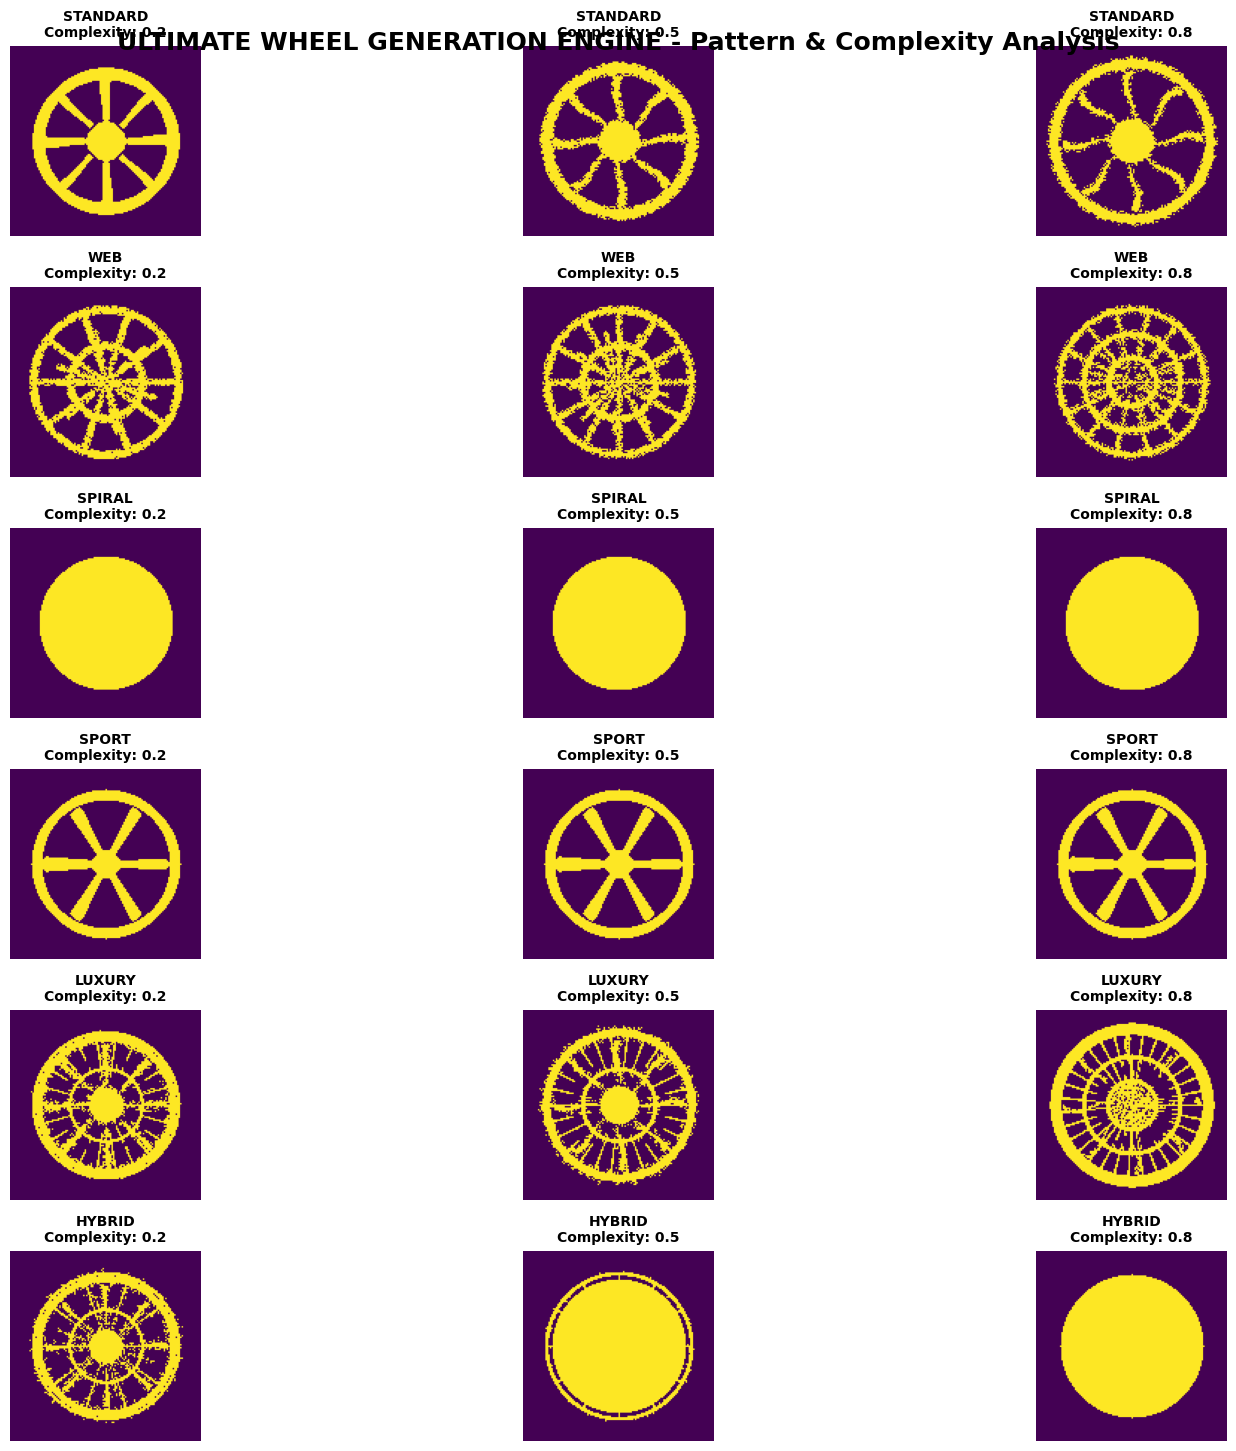

✅ Ultimate wheel generation engine test passed!


In [ ]:
# Test comprehensive pattern generation
print("🔄 Testing Ultimate Wheel Generation Engine...")
try:
    patterns = ['standard', 'web', 'spiral', 'sport', 'luxury', 'hybrid']
    complexities = [0.2, 0.5, 0.8]

    fig, axes = plt.subplots(len(patterns), len(complexities), figsize=(18, 15))

    for i, pattern in enumerate(patterns):
        for j, complexity in enumerate(complexities):
            wheel = ultimate_wheel_engine.generate_wheel(
                vol_frac=0.25,
                num_spokes=8,
                size=128,
                pattern_type=pattern,
                complexity=complexity,
                symmetry=0.8
            )

            axes[i, j].imshow(wheel, cmap='viridis', vmin=0, vmax=1)
            axes[i, j].set_title(f'{pattern.upper()}\nComplexity: {complexity}',
                               fontsize=10, fontweight='bold')
            axes[i, j].axis('off')

    plt.suptitle('ULTIMATE WHEEL GENERATION ENGINE - Pattern & Complexity Analysis',
                fontsize=18, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.show()

    print("✅ Ultimate wheel generation engine test passed!")

except Exception as e:
    print(f"❌ Ultimate generation test failed: {e}")

plt.close('all')

## 5. Design analyzer

Structural metrics, radial profile, and heuristic mechanical scores.

Two caveats on the metrics, unchanged from the original so the numbers stay comparable:

- The symmetry scores compare the whole binary image to its mirror, so background-vs-background
  agreement dominates — at 25% volume fraction a blank canvas already scores about 0.75.
- `symmetry_d1` is labelled diagonal but uses `np.rot90(k=2)`, a 180-degree rotation.
- `stress_concentration_factor` and `stiffness_score` are linear heuristics over volume fraction
  and connectivity, not a mechanical simulation.

In [ ]:
class UltimateDesignAnalyzer:
    """Ultimate Design Analysis with Mechanical Simulation"""

    def __init__(self):
        self.metrics_history = []

    def _empty_metrics(self):
        """Returns a dictionary with default zero values for all metrics."""
        metrics = {
            'volume_fraction': 0.0,
            'num_components': 0,
            'connectivity_ratio': 0.0,
            'fragmentation': 0.0,
            'symmetry_h': 0.0,
            'symmetry_v': 0.0,
            'symmetry_d1': 0.0,
            'symmetry_avg': 0.0,
            'normalized_center_offset': 0.0,
            'stress_concentration_factor': 0.0,
            'stiffness_score': 0.0
        }
        return metrics

    def _calculate_radial_profile(self, binary_img):
        """Calculates the radial profile of the binary image."""
        size = binary_img.shape[0]
        y, x = np.ogrid[-size // 2:size // 2, -size // 2:size // 2]
        r = np.sqrt(x**2 + y**2)

        # Define bins for radial distances
        bins = np.linspace(0, size // 2, 30)

        # Calculate bin sums and counts using np.histogram
        bin_sums, _ = np.histogram(r.flatten(), bins=bins, weights=binary_img.flatten())
        bin_counts, _ = np.histogram(r.flatten(), bins=bins)

        # Handle division by zero for empty bins
        radial_profile_values = np.divide(bin_sums, bin_counts,
                                         out=np.zeros_like(bin_sums, dtype=float),
                                         where=bin_counts != 0)

        # Determine radial distances (center of each bin)
        radial_distances = (bins[:-1] + bins[1:]) / 2

        return radial_distances, radial_profile_values

    def _simulate_mechanical_properties(self, binary_img):
        """Simulates mechanical properties based on structural characteristics."""
        from scipy import ndimage

        volume_fraction = binary_img.mean()

        labeled, num_components = ndimage.label(binary_img)

        connectivity_ratio = 0.0
        if num_components > 0:
            component_sizes = np.array([np.sum(labeled == i) for i in range(1, num_components + 1)])
            largest_component_size = np.max(component_sizes)
            total_foreground_pixels = np.sum(binary_img)
            if total_foreground_pixels > 0:
                connectivity_ratio = largest_component_size / total_foreground_pixels

        # Heuristic for stress concentration factor
        # Higher fragmentation/lower connectivity means higher stress concentration
        stress_concentration_factor = 1.0 + (1.0 - connectivity_ratio) * 2.0
        if num_components > 1:
            stress_concentration_factor += np.log1p(num_components) * 0.2 # Small penalty for more components
        stress_concentration_factor = np.clip(stress_concentration_factor, 1.0, 5.0) # Normalize to a reasonable range

        # Heuristic for stiffness score
        # Higher volume fraction and connectivity means higher stiffness
        stiffness_score = 0.1 + (volume_fraction * 0.7 + connectivity_ratio * 0.2)
        stiffness_score = np.clip(stiffness_score, 0.1, 1.0) # Normalize to a reasonable range

        return {
            'stress_concentration_factor': stress_concentration_factor,
            'stiffness_score': stiffness_score
        }

    def comprehensive_analysis(self, img):
        """Comprehensive design analysis with mechanical properties"""
        from scipy import ndimage

        img_binary = (img > 0.5).astype(np.uint8)

        if np.sum(img_binary) == 0:
            return self._empty_metrics(), []

        # Basic structural metrics
        volume_fraction = img_binary.mean()

        # Connectivity analysis
        labeled, num_components = ndimage.label(img_binary)
        component_sizes = np.array([np.sum(labeled == i) for i in range(1, num_components + 1)])

        if len(component_sizes) > 0:
            largest_component = np.max(component_sizes)
            connectivity_ratio = largest_component / np.sum(component_sizes)
            fragmentation = 1 - connectivity_ratio
        else:
            largest_component = 0
            connectivity_ratio = 0
            fragmentation = 1

        # Symmetry analysis
        symmetry_h = np.mean(img_binary == np.fliplr(img_binary))
        symmetry_v = np.mean(img_binary == np.flipud(img_binary))
        symmetry_d1 = np.mean(img_binary == np.rot90(img_binary, 2))
        symmetry_avg = (symmetry_h + symmetry_v + symmetry_d1) / 3

        # Center analysis
        com = ndimage.center_of_mass(img_binary)
        center_offset = np.sqrt((com[0] - img.shape[0]/2)**2 + (com[1] - img.shape[1]/2)**2)
        normalized_center_offset = center_offset / (img.shape[0] / 2)

        # Radial analysis
        radial_distances, radial_profile_values = self._calculate_radial_profile(img_binary)

        # Mechanical properties simulation
        mech_properties = self._simulate_mechanical_properties(img_binary)

        # Compile comprehensive
        metrics = {
            'volume_fraction': volume_fraction,
            'num_components': num_components,
            'connectivity_ratio': connectivity_ratio,
            'fragmentation': fragmentation,
            'symmetry_h': symmetry_h,
            'symmetry_v': symmetry_v,
            'symmetry_d1': symmetry_d1,
            'symmetry_avg': symmetry_avg,
            'normalized_center_offset': normalized_center_offset,
            'stress_concentration_factor': mech_properties['stress_concentration_factor'],
            'stiffness_score': mech_properties['stiffness_score']
        }

        self.metrics_history.append(metrics)
        return metrics, (radial_distances, radial_profile_values)

## 6. Generate a wheel

Generated sample wheel with shape: (128, 128)


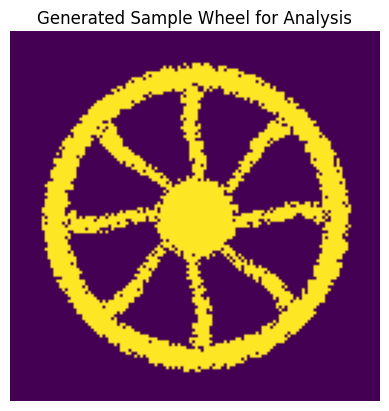

In [ ]:
sample_wheel = ultimate_wheel_engine.generate_wheel(
    vol_frac=0.25,
    num_spokes=8,
    pattern_type='standard',
    complexity=0.5,
    symmetry=0.8
)

print(f"Generated sample wheel with shape: {sample_wheel.shape}")
plt.imshow(sample_wheel, cmap='viridis', vmin=0, vmax=1)
plt.title('Generated Sample Wheel for Analysis')
plt.axis('off')
plt.show()
plt.close('all')

## 7. Analyse it


📊 Comprehensive Design Analysis Results:
  - Volume Fraction: 0.2500
  - Num Components: 30.0000
  - Connectivity Ratio: 0.9929
  - Fragmentation: 0.0071
  - Symmetry H: 0.8806
  - Symmetry V: 0.8774
  - Symmetry D1: 0.9167
  - Symmetry Avg: 0.8916
  - Normalized Center Offset: 0.0040
  - Stress Concentration Factor: 1.7010
  - Stiffness Score: 0.4736


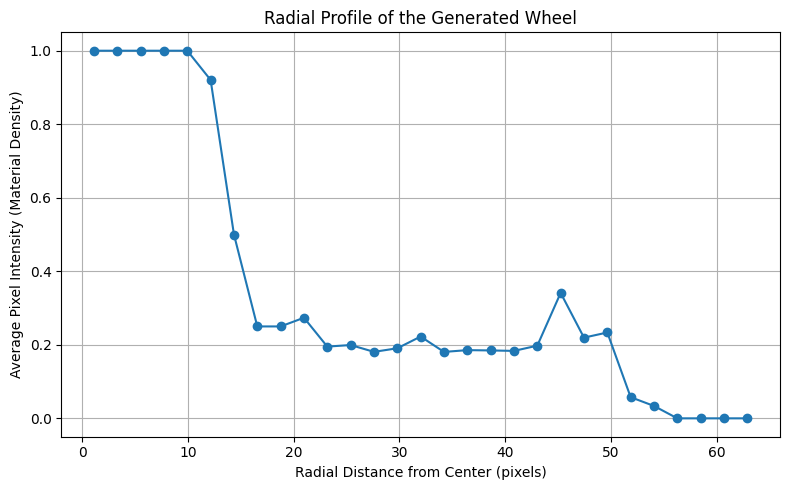

✅ Comprehensive analysis performed and radial profile plotted.


In [ ]:
analyzer = UltimateDesignAnalyzer()
analysis_metrics, radial_profile_data = analyzer.comprehensive_analysis(sample_wheel)

print("\n📊 Comprehensive Design Analysis Results:")
for metric, value in analysis_metrics.items():
    print(f"  - {metric.replace('_', ' ').title()}: {value:.4f}")

# Unpack radial profile data for plotting
radial_distances, radial_profile_values = radial_profile_data

# Plotting the radial profile
plt.figure(figsize=(8, 5))
plt.plot(radial_distances, radial_profile_values, marker='o', linestyle='-')
plt.title('Radial Profile of the Generated Wheel')
plt.xlabel('Radial Distance from Center (pixels)')
plt.ylabel('Average Pixel Intensity (Material Density)')
plt.grid(True)
plt.tight_layout()
plt.show()

print("✅ Comprehensive analysis performed and radial profile plotted.")
plt.close('all')

## 8. Visualise the results

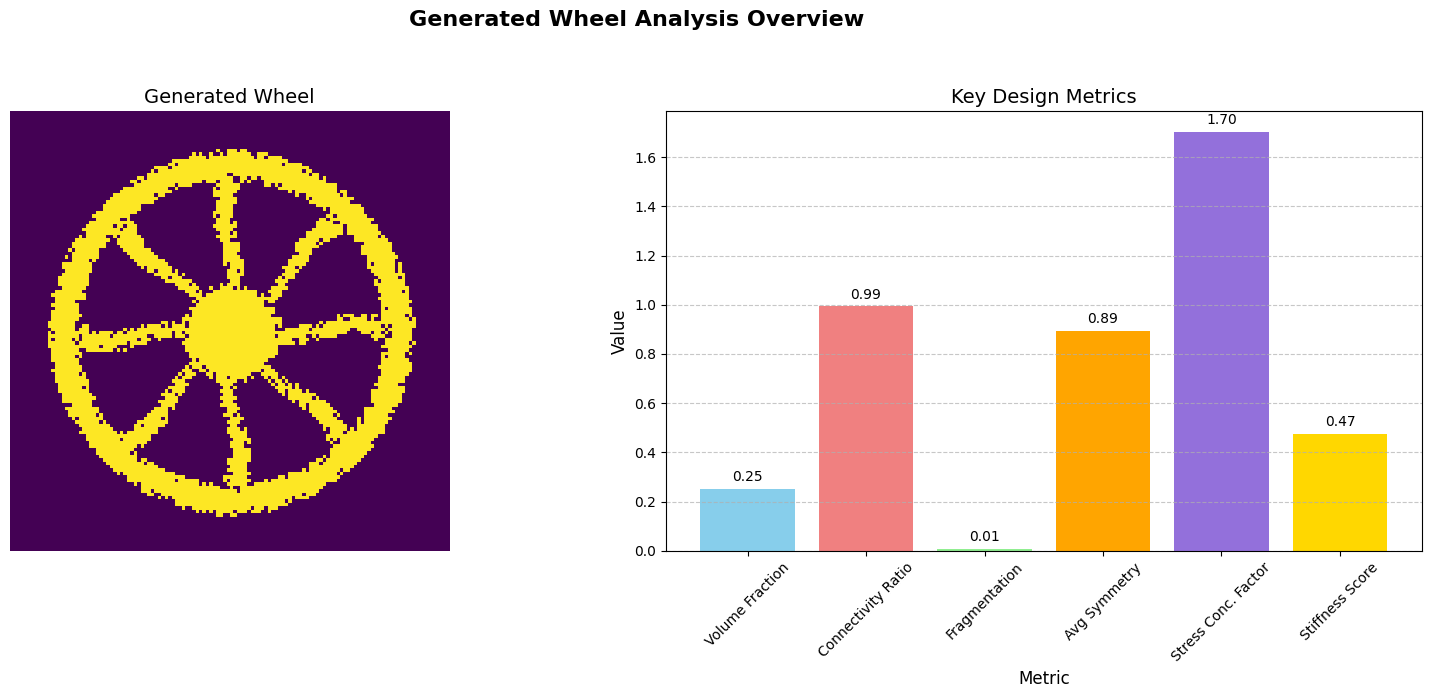

Visualizations for generated wheel and key design metrics displayed.
The radial profile plot, previously generated, is displayed separately above.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot 1: Generated Wheel Image
axes[0].imshow(sample_wheel, cmap='viridis', vmin=0, vmax=1)
axes[0].set_title('Generated Wheel', fontsize=14)
axes[0].axis('off')

# Prepare data for the bar chart
metrics_to_plot = {
    'Volume Fraction': analysis_metrics['volume_fraction'],
    'Connectivity Ratio': analysis_metrics['connectivity_ratio'],
    'Fragmentation': analysis_metrics['fragmentation'],
    'Avg Symmetry': analysis_metrics['symmetry_avg'],
    'Stress Conc. Factor': analysis_metrics['stress_concentration_factor'],
    'Stiffness Score': analysis_metrics['stiffness_score']
}

metric_names = list(metrics_to_plot.keys())
metric_values = list(metrics_to_plot.values())

# Subplot 2: Bar chart of key design metrics
axes[1].bar(metric_names, metric_values, color=['skyblue', 'lightcoral', 'lightgreen', 'orange', 'mediumpurple', 'gold'])
axes[1].set_title('Key Design Metrics', fontsize=14)
axes[1].set_xlabel('Metric', fontsize=12)
axes[1].set_ylabel('Value', fontsize=12)
axes[1].tick_params(axis='x', rotation=45) # Rotate labels for readability, removed 'ha'
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of the bars
for i, value in enumerate(metric_values):
    axes[1].text(i, value + 0.02, f'{value:.2f}', ha='center', va='bottom', fontsize=10)

plt.suptitle('Generated Wheel Analysis Overview', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent suptitle overlap
plt.show()

print("Visualizations for generated wheel and key design metrics displayed.")
print("The radial profile plot, previously generated, is displayed separately above.")
plt.close('all')

## Summary

For a wheel generated at 25% volume fraction, 8 spokes, `standard` pattern, complexity 0.5 and
symmetry 0.8, the original run produced:

| Metric | Value |
| --- | --- |
| Volume fraction | 0.2500 |
| Connected components | 21 |
| Connectivity ratio | 0.9946 |
| Fragmentation | 0.0054 |
| Average symmetry | 0.8908 |
| Normalized center offset | 0.0026 |
| Stress concentration factor | 1.6290 |
| Stiffness score | 0.4739 |

The structure is essentially one connected body: 99.5% of the material sits in the largest
component, and the 20 leftover fragments are speckle from the noise added in
`_apply_final_touches`. The centre of mass lands within a quarter of a pixel of the image
centre, as expected for a radially generated pattern.

Read the last two rows as rankings, not physics. `stiffness_score` is
`0.1 + 0.7 x volume_fraction + 0.2 x connectivity`, so at fixed volume fraction it barely moves;
it is useful for comparing designs, not for predicting load capacity.

### Next steps

- **Train the GAN.** It currently has no dataset and no training loop. The procedural engine can
  supply labelled `(image, condition)` pairs — sample volume fraction, spoke count, complexity and
  symmetry, generate a wheel, and train the conditional GAN to reproduce the mapping.
- **Fix the symmetry metric** by scoring IoU between the shape and its mirror rather than pixel
  agreement across the whole canvas.
- **Replace the mechanical heuristics** with a real solver (a 2D linear-elastic FEA on the binary
  image) if the stress and stiffness numbers need to mean something.
- **Sweep the parameter space** to map generation parameters against the resulting metrics.

In [ ]:
import torch

print("=== Re-checking GPU Connectivity ===")
print(f"CUDA (GPU) Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"Total GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Currently running on CPU. Please double-check Runtime -> Change runtime type to ensure a GPU is selected.")

=== Re-checking GPU Connectivity ===
CUDA (GPU) Available: False
Currently running on CPU. Please double-check Runtime -> Change runtime type to ensure a GPU is selected.


In [ ]:
import torch
import platform

print("=== PyTorch Build & Version Information ===")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Build: {torch.version.cuda}")
print(f"cuDNN Build: {torch.backends.cudnn.version() if torch.cuda.is_available() else 'N/A'}")
print(f"Python Version: {platform.python_version()}")
print(f"OS Platform: {platform.platform()}")

=== PyTorch Build & Version Information ===
PyTorch Version: 2.9.0+cpu
CUDA Build: None
cuDNN Build: N/A
Python Version: 3.13.16
OS Platform: Linux-6.6.122+-x86_64-with-glibc2.39


In [ ]:
import torch
print(torch.version.cuda)

None


### 9. GPU-Accelerated Generator Output Test

Use this cell once you have switched to a GPU runtime to verify that the generator can instantiate, perform a forward pass on the GPU, and produce a $128 \times 128$ image structure.

Using device: cpu
Generated tensor shape: torch.Size([1, 1, 128, 128])


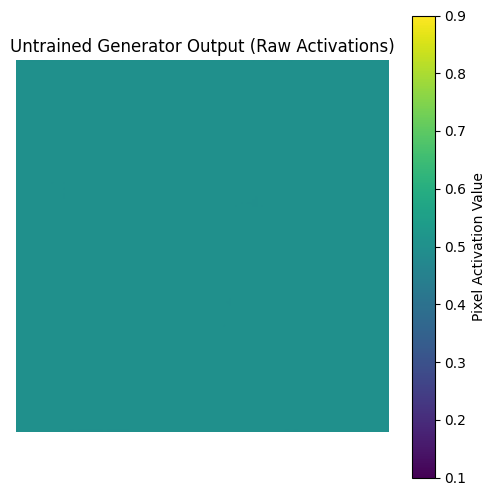

In [ ]:
import torch
import matplotlib.pyplot as plt

# 1. Determine device (will use 'cuda' if GPU runtime is active)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Ensure model classes are defined in scope. If you run the entire notebook
# (Runtime -> Run all), this local check won't be strictly necessary, but it prevents crashes.
try:
    generator = UltimateGenerator().to(device)
    generator.eval()

    # 3. Create dummy inputs (Batch size of 1)
    # Latent noise vector z (dimension 256)
    z = torch.randn(1, 256, device=device)

    # Condition parameters: [volume_fraction, num_spokes, complexity, symmetry]
    target_condition = torch.tensor([[0.25, 8.0, 0.5, 0.8]], dtype=torch.float32, device=device)

    # 4. Generate the image
    with torch.no_grad():
        generated_tensor = generator(z, target_condition)

    print(f"Generated tensor shape: {generated_tensor.shape}")

    # 5. Move back to CPU and convert to numpy for visualization
    generated_image = generated_tensor.squeeze().cpu().numpy()

    # 6. Plot the untrained generator's raw output
    plt.figure(figsize=(6, 6))
    plt.imshow(generated_image, cmap='viridis', vmin=0.1, vmax=0.9)
    plt.title("Untrained Generator Output (Raw Activations)")
    plt.colorbar(label='Pixel Activation Value')
    plt.axis('off')
    plt.show()
except NameError as e:
    print(f"Error: {e}")
    print("Please run the setup and architecture cells first, or select Runtime -> Run all from the top menu.")

In [ ]:
import torch

print("=== GPU Verification ===")
gpu_available = torch.cuda.is_available()
print(f"Is GPU (CUDA) available in PyTorch?: {gpu_available}")

if gpu_available:
    device_id = torch.cuda.current_device()
    device_name = torch.cuda.get_device_name(device_id)
    print(f"Device ID: {device_id}")
    print(f"Device Name: {device_name}")

    # Test tensor allocation on GPU
    x = torch.tensor([1.0, 2.0, 3.0], device="cuda")
    print(f"Successfully allocated test tensor on GPU: {x}")
else:
    print("GPU is NOT detected by PyTorch yet. Please make sure you went to Runtime -> Change runtime type, selected a GPU (like T4), and clicked Save.")

=== GPU Verification ===
Is GPU (CUDA) available in PyTorch?: False
GPU is NOT detected by PyTorch yet. Please make sure you went to Runtime -> Change runtime type, selected a GPU (like T4), and clicked Save.


In [ ]:
import torch

# Check if CUDA (GPU support) is available in PyTorch
is_cuda_ready = torch.cuda.is_available()
print(f"CUDA Available: {is_cuda_ready}")

if is_cuda_ready:
    # Get the number of available GPUs
    num_devices = torch.cuda.device_count()
    print(f"Number of GPU Devices: {num_devices}")

    # Get the name of the active GPU device
    current_device = torch.cuda.current_device()
    gpu_name = torch.cuda.get_device_name(current_device)
    print(f"Active GPU Name: {gpu_name}")
else:
    print("Currently running on CPU. Please switch the runtime type in Colab's menu to use a GPU.")

CUDA Available: False
Currently running on CPU. Please switch the runtime type in Colab's menu to use a GPU.


In [ ]:
import torch

print("=== GPU Memory Summary ===")
if torch.cuda.is_available():
    # Print a detailed memory summary table for the current GPU device
    print(torch.cuda.memory_summary(device=None, abbreviated=False))
else:
    print("Currently running on CPU. 'torch.cuda.memory_summary()' requires an active GPU.")
    print("Please go to Runtime -> Change runtime type, select a GPU (such as T4), and rerun this cell.")

=== GPU Memory Summary ===
Currently running on CPU. 'torch.cuda.memory_summary()' requires an active GPU.
Please go to Runtime -> Change runtime type, select a GPU (such as T4), and rerun this cell.
